# EDA bis — volumes crop 130 mm

Exploration des NPZ produits par les kernels Kaggle `convert-crop130` (`data/crop130/`).

**Différence vs `02_eda.ipynb` / `volumes.zip` communautaires**

| | NPZ communautaires | crop 130 mm |
|---|---|---|
| Séries | 24 371 (toutes) | ~3 / étude (fluid-prioritaire, sag/cor/ax) |
| Crop spatial | FOV complet → 224 | **130 mm** au centre (`PixelSpacing`), sinon 70 % |
| Profondeur | linspace 24 sur **toute** la pile | bande **20–80 %**, puis linspace 24 |
| Intensité | déjà normalisée | percentiles 1–99 → uint8 |

Objectif : vérifier que le genou est bien cadré, que la bande profondeur a du sens, et comparer visuellement à l'ancien NPZ (même `SeriesInstanceUID`).


In [1]:
from __future__ import annotations

from pathlib import Path
import io
import json
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

CSV = ROOT / "data" / "csv"
CROP = ROOT / "data" / "crop130"
OLD_ZIP = ROOT / "data" / "volumes.zip"

PLANES = ["Sagittal", "Coronal", "Axial"]
LABELS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
ZS = [0, 6, 12, 17, 23]

train = pd.read_csv(CSV / "train.csv")
series = pd.read_csv(CSV / "train_series.csv")
labeled = train[train[LABELS].notna().all(axis=1)].copy()

zips, index = [], {}
for p in sorted(CROP.glob("volumes_crop130_part*.zip")):
    z = zipfile.ZipFile(p)
    zips.append(z)
    for n in z.namelist():
        if n.endswith(".npz"):
            index[Path(n).stem] = z
    print(p.name, "->", sum(n.endswith(".npz") for n in z.namelist()), "npz")

assert index, f"aucun zip dans {CROP}"


def load_new(series_uid: str) -> np.ndarray:
    z = index[series_uid]
    return np.load(io.BytesIO(z.read(f"{series_uid}.npz")))["data"]


old_z = zipfile.ZipFile(OLD_ZIP) if OLD_ZIP.exists() else None


def load_old(series_uid: str) -> np.ndarray:
    return np.load(io.BytesIO(old_z.read(f"{series_uid}.npz")))["data"]


print("séries crop130 :", len(index))
print("old zip        :", OLD_ZIP.exists())


volumes_crop130_part0.zip -> 6611 npz
volumes_crop130_part1.zip -> 6608 npz
séries crop130 : 13219
old zip        : True


## 1. Inventaire + recette

Les manifests listent **une ligne par série convertie** (succès ou échec). `RECIPE.json` fige crop / bande / 24 / 224.


In [2]:
manifests = list(CROP.glob("manifest_part*.csv"))
man = pd.concat([pd.read_csv(p) for p in manifests], ignore_index=True)
print("manifest :", len(man), "lignes")
print(man["ok"].value_counts().rename("n").to_string())
print()
fails = man[man["ok"] == 0]
print("échecs :", len(fails))
if len(fails):
    display(fails[["StudyInstanceUID", "SeriesInstanceUID", "plane", "error"]].head(10))

recipe_path = CROP / "RECIPE.json"
if recipe_path.exists():
    print("\nRECIPE")
    print(json.dumps(json.loads(recipe_path.read_text(encoding="utf-8")), indent=2))

npz_ids = set(index)
print()
print("études distinctes (ok) :", man.loc[man.ok == 1, "StudyInstanceUID"].nunique())
print("études train           :", train.StudyInstanceUID.nunique())
print("études train sans crop :", len(set(train.StudyInstanceUID) - set(man.loc[man.ok == 1, "StudyInstanceUID"])))
print("séries train sans npz  :", len(set(series.SeriesInstanceUID) - npz_ids),
      "(normal : on n'a gardé que 3 plans fluid / étude)")


manifest : 13221 lignes
ok
1    13219
0        2

échecs : 2


,StudyInstanceUID,SeriesInstanceUID,plane,error
3147,1.2.826.0.1.3680043.8.498.37833587429731221455...,1.2.826.0.1.3680043.8.498.31160785238781353848...,Coronal,ValueError: The number of bytes of pixel data ...
9574,1.2.826.0.1.3680043.8.498.34685905030370793639...,1.2.826.0.1.3680043.8.498.39396636671446532796...,Axial,ValueError: The number of bytes of pixel data ...



RECIPE
{
  "crop_mm": 130.0,
  "crop_rel": 0.7,
  "band": [
    0.2,
    0.8
  ],
  "n_slices": 24,
  "img_size": 224,
  "planes": [
    "Sagittal",
    "Coronal",
    "Axial"
  ],
  "shard_id": 0,
  "n_shards": 2,
  "n_jobs": 6612,
  "note": "1 serie fluid-prioritaire par plan. Crop 130 mm (PixelSpacing) sinon centre 70 %. Bande profondeur 20-80 %, linspace 24, resize 224, uint8."
}

études distinctes (ok) : 4407
études train           : 4407
études train sans crop : 0
séries train sans npz  : 11152 (normal : on n'a gardé que 3 plans fluid / étude)


## 2. Métadonnées de conversion

- `n_raw` : nombre de coupes DICOM avant sous-échantillonnage
- `band` : indices gardés (20–80 %). Largeur de bande = `b - a + 1`
- si bande **> 24** → on saute des coupes ; si **< 24** → on répète des indices
- `crop_mode` : `mm` (130 mm réel) vs `rel` (centre 70 %)
- `src_hw` : taille après crop spatial, avant resize 224


crop_mode
crop_mode
mm    13219

         n_raw   band_n    src_h     nbytes
count  13219.0  13219.0  13219.0    13219.0
mean      34.8     22.2    414.0   962454.9
std       30.8     18.5    141.5    86913.6
min       12.0      8.0    139.0   496524.0
25%       26.0     17.0    312.0   912291.0
50%       30.0     20.0    403.0   976035.0
75%       34.0     22.0    520.0  1025502.0
max      320.0    194.0   1040.0  1158116.0

bande < 24 (doublons d'indices) : 11386
bande = 24                      : 391
bande > 24 (sauts)              : 1442


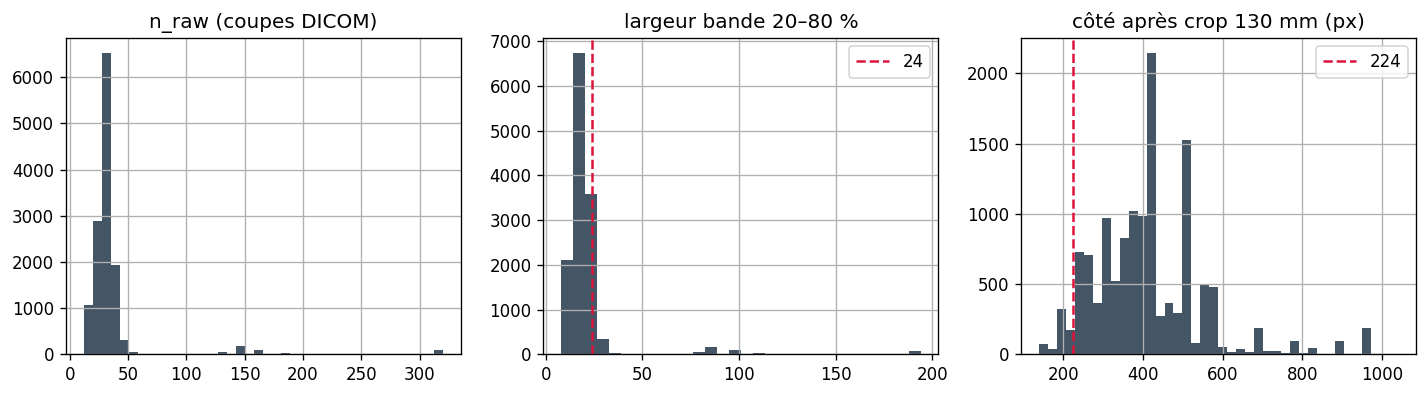


par plan


,n_raw,band_n,src_h
plane,,,
Axial,32.0,20.0,401.0
Coronal,30.0,20.0,406.0
Sagittal,30.0,20.0,392.0


In [3]:
ok = man[man["ok"] == 1].copy()

def parse_pair(s):
    if pd.isna(s):
        return np.nan, np.nan
    s = str(s).strip("[]")
    parts = [p.strip() for p in s.split(",")]
    return float(parts[0]), float(parts[1])

ok["band_lo"] = ok["band"].map(lambda s: parse_pair(s)[0])
ok["band_hi"] = ok["band"].map(lambda s: parse_pair(s)[1])
ok["band_n"] = ok["band_hi"] - ok["band_lo"] + 1
ok["src_h"] = ok["src_hw"].map(lambda s: parse_pair(s)[0])

print("crop_mode")
print(ok["crop_mode"].value_counts().to_string())
print()
print(ok[["n_raw", "band_n", "src_h", "nbytes"]].describe().round(1).to_string())
print()
print("bande < 24 (doublons d'indices) :", int((ok.band_n < 24).sum()))
print("bande = 24                      :", int((ok.band_n == 24).sum()))
print("bande > 24 (sauts)              :", int((ok.band_n > 24).sum()))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ok["n_raw"].hist(bins=40, ax=axes[0], color="#456")
axes[0].set_title("n_raw (coupes DICOM)")
ok["band_n"].hist(bins=30, ax=axes[1], color="#456")
axes[1].axvline(24, color="crimson", ls="--", label="24")
axes[1].set_title("largeur bande 20–80 %")
axes[1].legend()
ok["src_h"].hist(bins=40, ax=axes[2], color="#456")
axes[2].axvline(224, color="crimson", ls="--", label="224")
axes[2].set_title("côté après crop 130 mm (px)")
axes[2].legend()
plt.tight_layout()
plt.show()

print()
print("par plan")
display(ok.groupby("plane")[["n_raw", "band_n", "src_h"]].median().round(1))


## 3. Intensités des nouveaux NPZ

Échantillon de 150 séries. Les moments **ne doivent pas** coller aux NPZ communautaires (mean~42) : le crop zoome le genou (plus de signal, moins de fond noir).


shapes uniques : ['(24, 224, 224)']
dtypes         : ['uint8']
         mean     std  nonzero
count  150.00  150.00   150.00
mean    77.54   55.71     0.85
std     22.81    9.98     0.10
min     30.95   32.27     0.55
25%     59.19   48.44     0.78
50%     78.68   54.71     0.87
75%     93.94   62.90     0.92
max    150.08   82.14     1.00


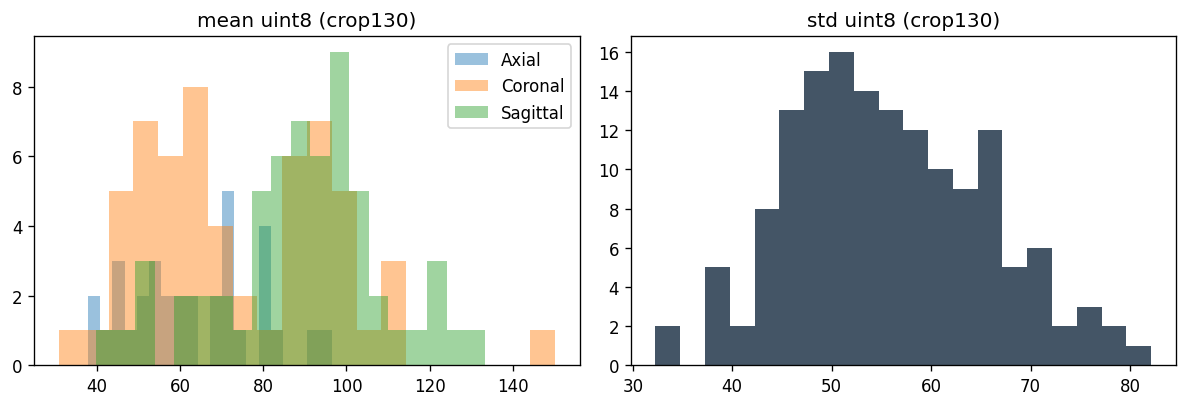

In [4]:
rng = np.random.default_rng(0)
sample_ids = rng.choice(list(index), size=min(150, len(index)), replace=False)
meta = ok.set_index("SeriesInstanceUID")

rows = []
for uid in sample_ids:
    v = load_new(uid)
    rec = {
        "uid": uid,
        "mean": float(v.mean()),
        "std": float(v.std()),
        "nonzero": float((v > 5).mean()),
        "shape": v.shape,
        "dtype": str(v.dtype),
    }
    if uid in meta.index:
        rec["plane"] = meta.loc[uid, "plane"]
        rec["n_raw"] = meta.loc[uid, "n_raw"]
    rows.append(rec)
inten = pd.DataFrame(rows)
print("shapes uniques :", inten["shape"].astype(str).unique())
print("dtypes         :", inten["dtype"].unique())
print(inten[["mean", "std", "nonzero"]].describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
if "plane" in inten:
    for plane, g in inten.groupby("plane"):
        axes[0].hist(g["mean"], bins=20, alpha=0.45, label=plane)
    axes[0].legend()
else:
    axes[0].hist(inten["mean"], bins=20)
axes[0].set_title("mean uint8 (crop130)")
axes[1].hist(inten["std"], bins=20, color="#456")
axes[1].set_title("std uint8 (crop130)")
plt.tight_layout()
plt.show()


## 4. Galerie — une étude, 3 plans (crop130)

Coupes `z = 0, 6, 12, 17, 23`. On prend une étude **gold** si elle est dans le zip.


étude : 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
positifs gold : ['PF OA', 'Effusion']


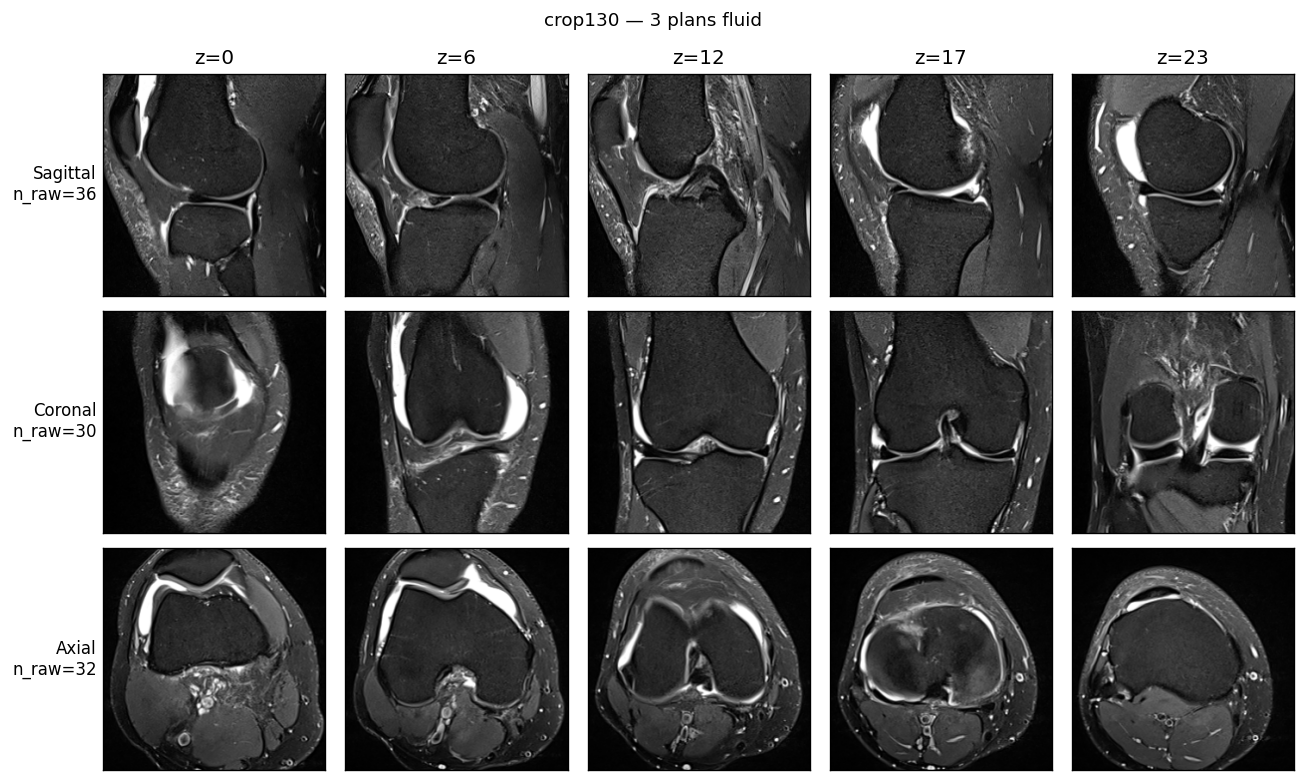

In [5]:
def show_study_new(study_uid: str, title: str = ""):
    rows = ok[ok.StudyInstanceUID == study_uid]
    fig, axes = plt.subplots(len(PLANES), len(ZS), figsize=(11, 6.6))
    for i, plane in enumerate(PLANES):
        hit = rows[rows.plane == plane]
        if hit.empty:
            for ax in axes[i]:
                ax.axis("off")
            continue
        uid = hit.SeriesInstanceUID.iloc[0]
        v = load_new(uid)
        n_raw = hit.n_raw.iloc[0]
        for ax, j in zip(axes[i], ZS):
            ax.imshow(v[j], cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title(f"z={j}")
        axes[i][0].set_ylabel(f"{plane}\nn_raw={int(n_raw)}", rotation=0, ha="right", va="center")
    fig.suptitle(title or study_uid[-28:], fontsize=11)
    plt.tight_layout()
    plt.show()


gold_ok = [u for u in labeled.StudyInstanceUID if u in set(ok.StudyInstanceUID)]
study = gold_ok[0] if gold_ok else ok.StudyInstanceUID.iloc[0]
row = train.set_index("StudyInstanceUID").loc[study]
pos = [c for c in LABELS if c in row.index and row[c] == 1]
print("étude :", study)
print("positifs gold :", pos if gold_ok else "(pas gold)")
show_study_new(study, title="crop130 — 3 plans fluid")


## 5. Avant / après — même série (communautaire vs crop130)

Le crop 130 mm doit **zoomer** le genou (moins de FOV, ligaments plus gros). Si l'ancien NPZ est déjà très cadré, la différence est faible.


séries dans les deux zips : 13219


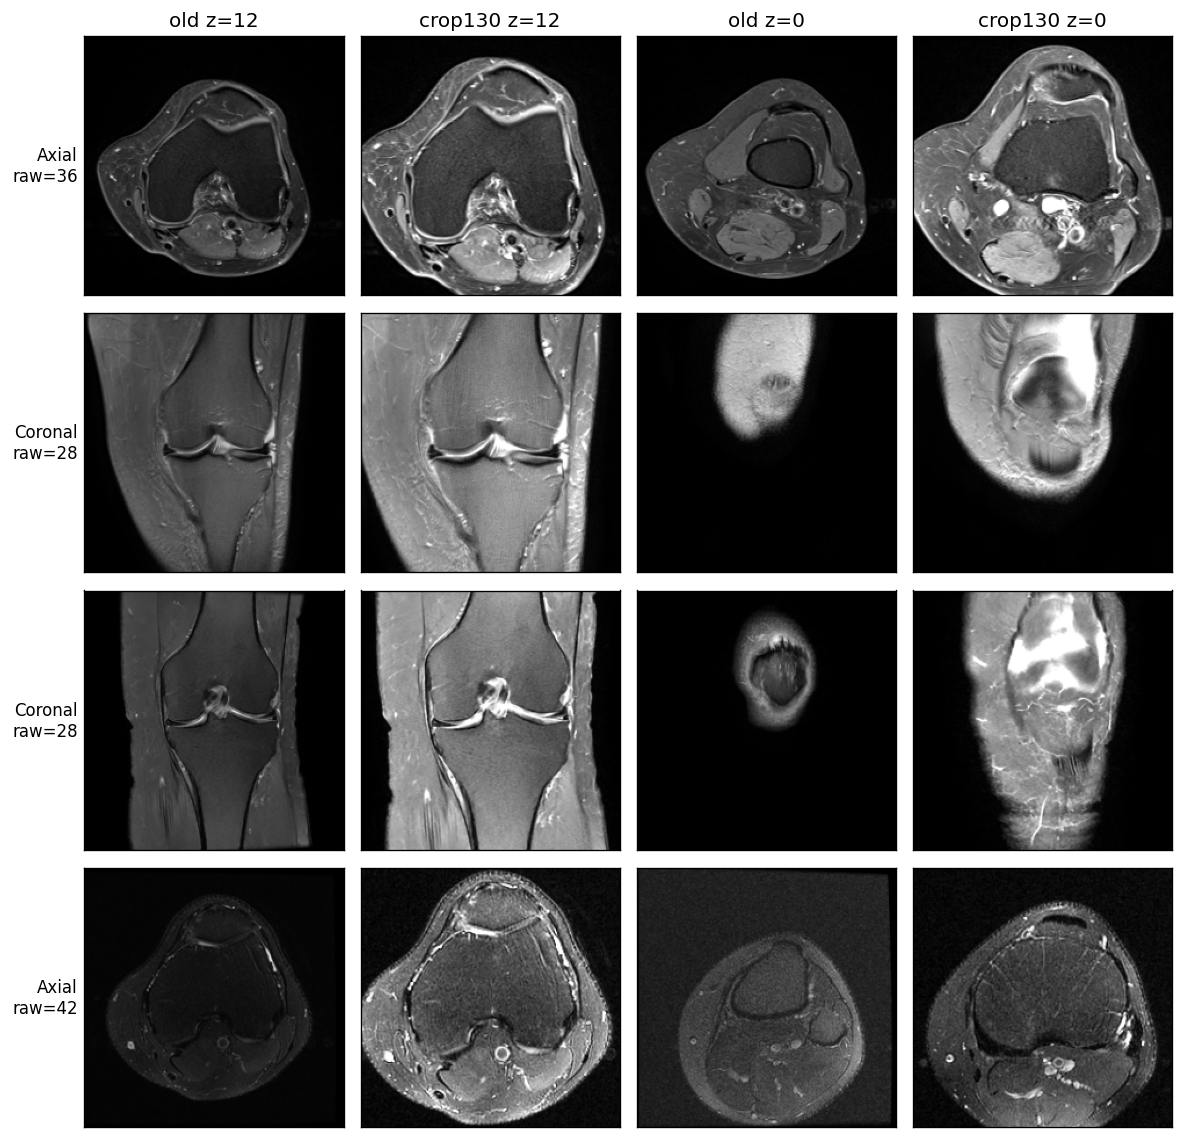

In [6]:
if old_z is None:
    print("data/volumes.zip absent — skip comparaison")
else:
    old_ids = {Path(n).stem for n in old_z.namelist() if n.endswith(".npz")}
    both = [u for u in index if u in old_ids]
    print("séries dans les deux zips :", len(both))
    rng = np.random.default_rng(1)
    picks = list(rng.choice(both, size=min(4, len(both)), replace=False))

    fig, axes = plt.subplots(len(picks), 4, figsize=(10, 2.4 * len(picks)))
    if len(picks) == 1:
        axes = np.expand_dims(axes, 0)
    for i, uid in enumerate(picks):
        a, b = load_old(uid), load_new(uid)
        m = ok.set_index("SeriesInstanceUID").loc[uid]
        axes[i, 0].imshow(a[12], cmap="gray", vmin=0, vmax=255)
        axes[i, 1].imshow(b[12], cmap="gray", vmin=0, vmax=255)
        axes[i, 2].imshow(a[0], cmap="gray", vmin=0, vmax=255)
        axes[i, 3].imshow(b[0], cmap="gray", vmin=0, vmax=255)
        axes[i, 0].set_ylabel(f"{m.plane}\nraw={int(m.n_raw)}", rotation=0, ha="right", va="center")
        for ax in axes[i]:
            ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            axes[i, 0].set_title("old z=12")
            axes[i, 1].set_title("crop130 z=12")
            axes[i, 2].set_title("old z=0")
            axes[i, 3].set_title("crop130 z=0")
    plt.tight_layout()
    plt.show()


## 6. Série courte vs longue

- **courte** (`band_n` < 24) : linspace répète des coupes → z=0 et z=6 peuvent être quasi identiques
- **longue** (`band_n` >> 24) : on saute des coupes dans la bande 20–80 %


n courtes : 11386 | n longues (>32 dans la bande) : 460


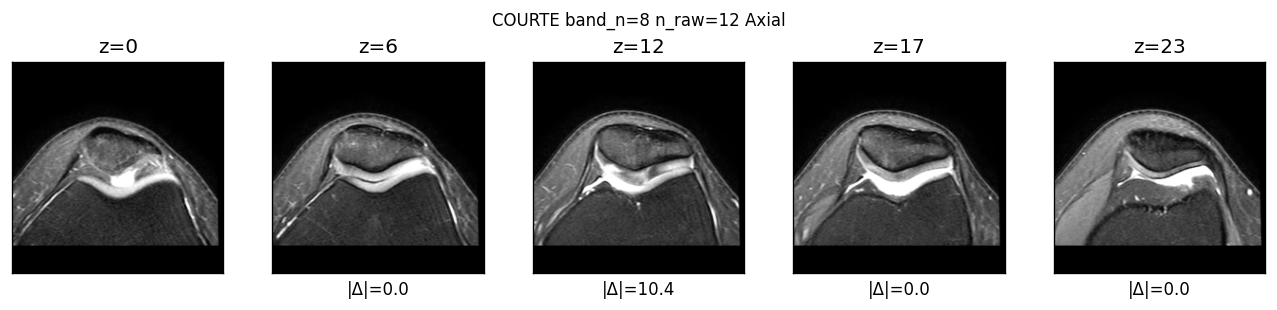

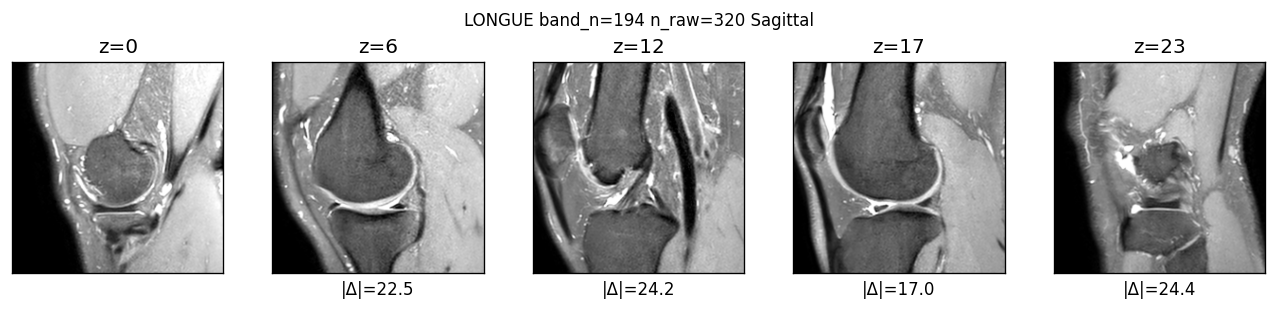

In [7]:
short = ok[ok.band_n < 24].sort_values("band_n")
long = ok[ok.band_n > 32].sort_values("band_n", ascending=False)
print("n courtes :", len(short), "| n longues (>32 dans la bande) :", len(long))


def show_depth(uid: str, title: str):
    v = load_new(uid)
    fig, axes = plt.subplots(1, len(ZS), figsize=(11, 2.4))
    for ax, j in zip(axes, ZS):
        ax.imshow(v[j], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"z={j}")
        ax.set_xticks([]); ax.set_yticks([])
        if j > 0:
            d = float(np.mean(np.abs(v[j].astype(np.float32) - v[j - 1].astype(np.float32))))
            ax.set_xlabel(f"|Δ|={d:.1f}")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


if len(short):
    r = short.iloc[0]
    show_depth(r.SeriesInstanceUID, f"COURTE band_n={int(r.band_n)} n_raw={int(r.n_raw)} {r.plane}")
if len(long):
    r = long.iloc[0]
    show_depth(r.SeriesInstanceUID, f"LONGUE band_n={int(r.band_n)} n_raw={int(r.n_raw)} {r.plane}")


## 7. Ce qu'il faut retenir pour le train

- Les NPZ sont au **même format** `(24, 224, 224)` uint8 → KneeNet actuel se branche sans changer le modèle.
- Il faudra un **lecteur 2 zip** (part0 + part1) et n'utiliser que les `SeriesInstanceUID` présents.
- Au submit : **reproduire la recette** (crop 130 mm + bande 20–80 %), pas le pipeline des NPZ communautaires.
- Moments plus hauts (genou zoomé) → **recalculer `NORM_MEAN` / `NORM_STD`** avant d'entraîner.
- Vérifier visuellement qu'on ne coupe pas le genou (crop 130 mm trop serré / genou hors-centre).
